<a href="https://colab.research.google.com/github/akhilamarepally/ML/blob/main/ML_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import joblib
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Download UCI Bank Marketing dataset

bank_marketing = fetch_ucirepo(id=222)

# Input features
X_original = bank_marketing.data.features

# Original target
y_original = bank_marketing.data.targets

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
df = X_original.copy()

# Add original UCI target
df["subscription"] = y_original["y"]

print("Dataset created successfully!")
display(df.head())

Dataset created successfully!


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,subscription
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 45211
Number of columns: 17


In [6]:
print("Column names:")

for i, column in enumerate(df.columns, 1):
    print(i, ".", column)

Column names:
1 . age
2 . job
3 . marital
4 . education
5 . default
6 . balance
7 . housing
8 . loan
9 . contact
10 . day_of_week
11 . month
12 . duration
13 . campaign
14 . pdays
15 . previous
16 . poutcome
17 . subscription


In [7]:
print("Data Types:")
print(df.dtypes)

Data Types:
age              int64
job             object
marital         object
education       object
default         object
balance          int64
housing         object
loan            object
contact         object
day_of_week      int64
month           object
duration         int64
campaign         int64
pdays            int64
previous         int64
poutcome        object
subscription    object
dtype: object


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age           45211 non-null  int64 
 1   job           44923 non-null  object
 2   marital       45211 non-null  object
 3   education     43354 non-null  object
 4   default       45211 non-null  object
 5   balance       45211 non-null  int64 
 6   housing       45211 non-null  object
 7   loan          45211 non-null  object
 8   contact       32191 non-null  object
 9   day_of_week   45211 non-null  int64 
 10  month         45211 non-null  object
 11  duration      45211 non-null  int64 
 12  campaign      45211 non-null  int64 
 13  pdays         45211 non-null  int64 
 14  previous      45211 non-null  int64 
 15  poutcome      8252 non-null   object
 16  subscription  45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [9]:
missing_values = df.isnull().sum()

print("Missing values:")
display(missing_values)

Missing values:


,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [10]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [11]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(45211, 17)


In [12]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 age
[58 44 33 47 35 28 42 43 41 29 53 57 51 45 60 56 32 25 40 39]

 job
['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']

 marital
['married' 'single' 'divorced']

 education
['tertiary' 'secondary' nan 'primary']

 default
['no' 'yes']

 balance
[2143   29    2 1506    1  231  447  121  593  270  390    6   71  162
  229   13   52   60    0  723]

 housing
['yes' 'no']

 loan
['no' 'yes']

 contact
[nan 'cellular' 'telephone']

 day_of_week
[ 5  6  7  8  9 12 13 14 15 16 19 20 21 23 26 27 28 29 30  2]

 month
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

 duration
[261 151  76  92 198 139 217 380  50  55 222 137 517  71 174 353  98  38
 219  54]

 campaign
[ 1  2  3  5  4  6  7  8  9 10 11 12 13 19 14 24 16 32 18 22]

 pdays
[ -1 151 166  91  86 143 147  89 140 176 101 174 170 167 195 165 129 188
 196 172]

 previous
[ 0  3  1  4  2 11 16  6  5 10 12  7 18  9 21

In [13]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,44923,11,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,43354,3,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,32191,2,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [14]:
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'subscription']


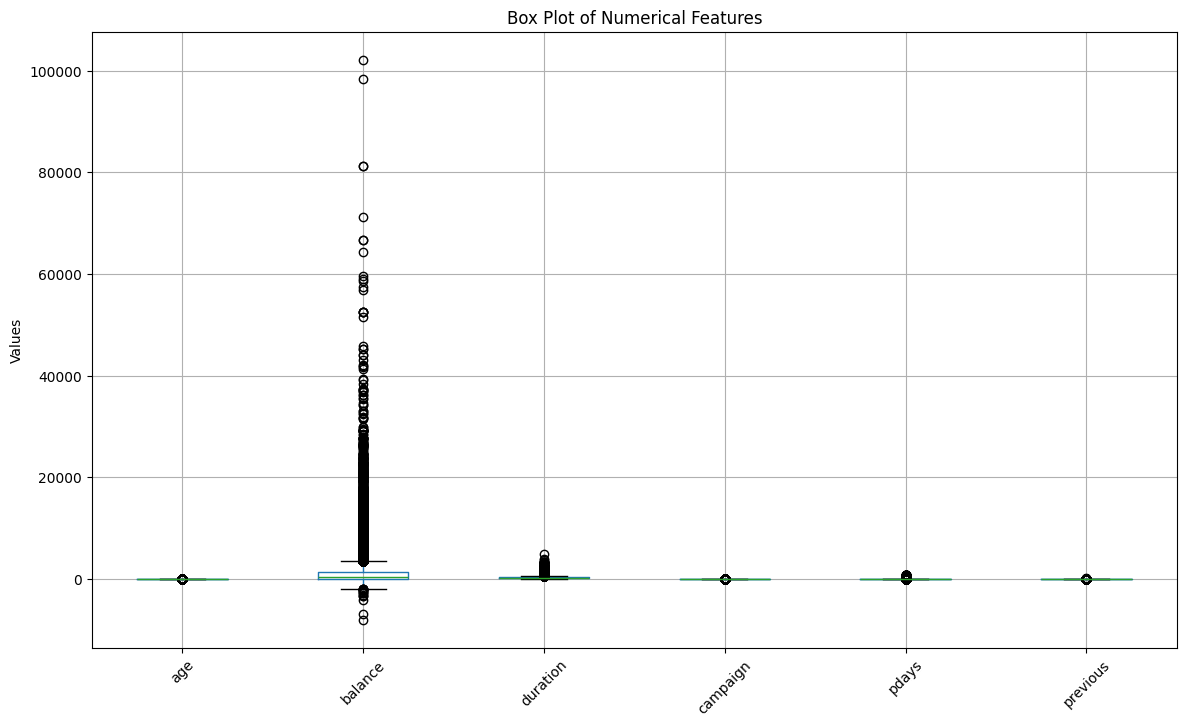

In [15]:
important_numeric = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

plt.figure(figsize=(14, 8))

df[important_numeric].boxplot()

plt.title("Box Plot of Numerical Features")
plt.ylabel("Values")
plt.xticks(rotation=45)

plt.show()

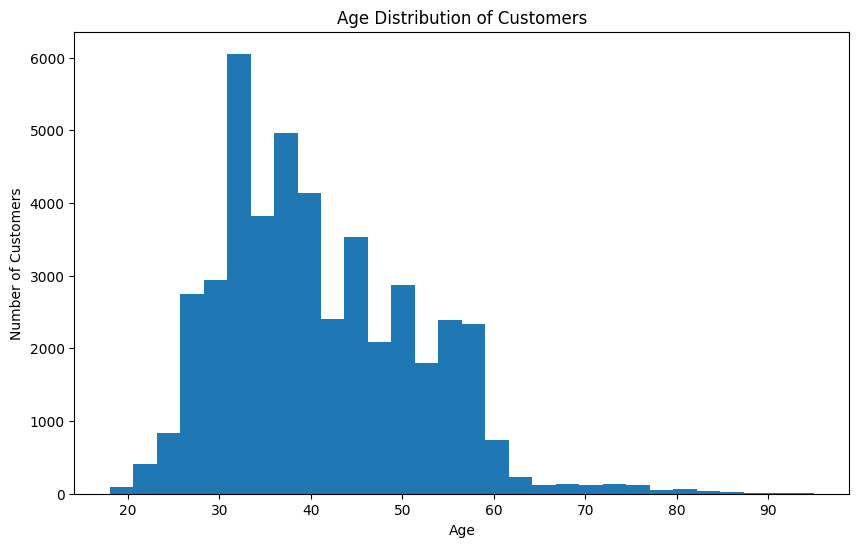

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["age"],
    bins=30
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

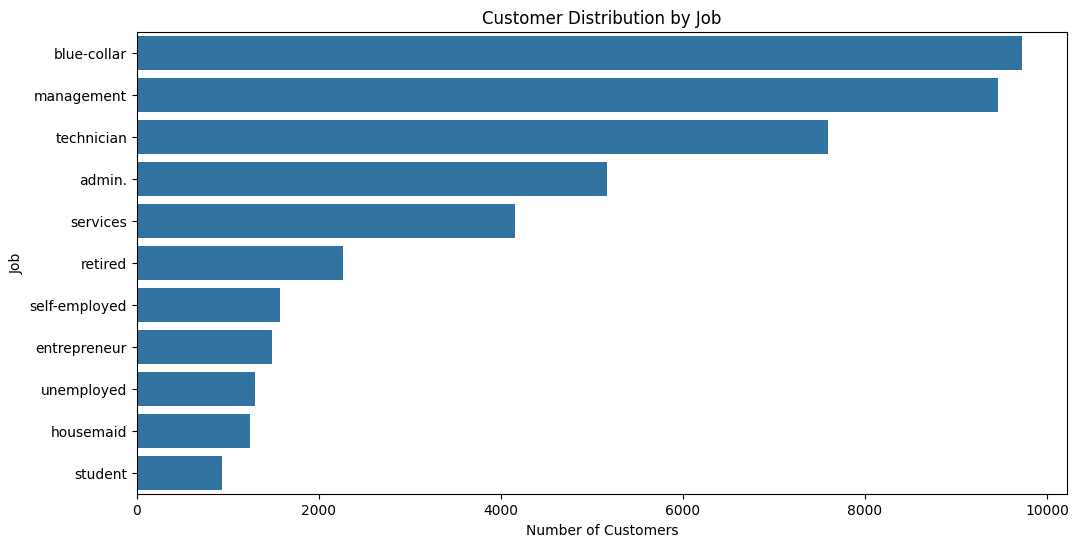

In [17]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="job",
    order=df["job"].value_counts().index
)

plt.title("Customer Distribution by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job")

plt.show()

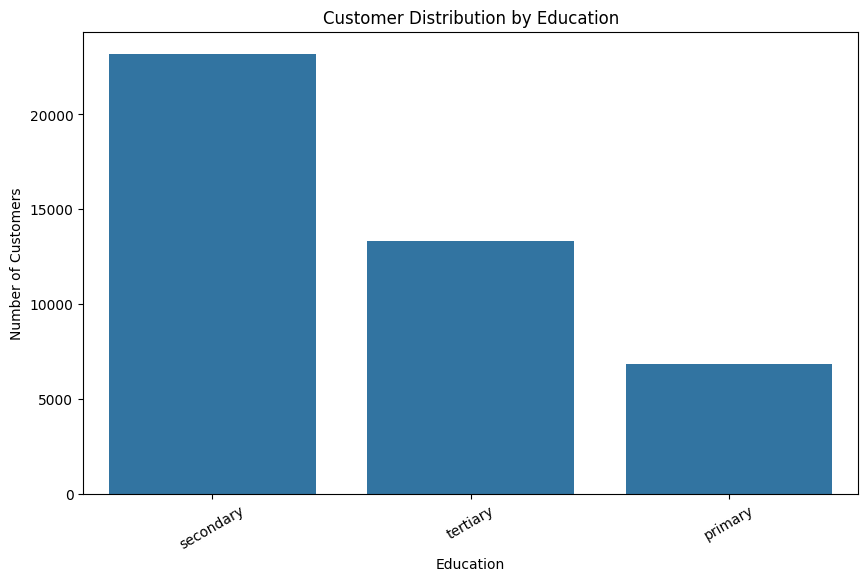

In [18]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="education",
    order=df["education"].value_counts().index
)

plt.title("Customer Distribution by Education")
plt.xlabel("Education")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

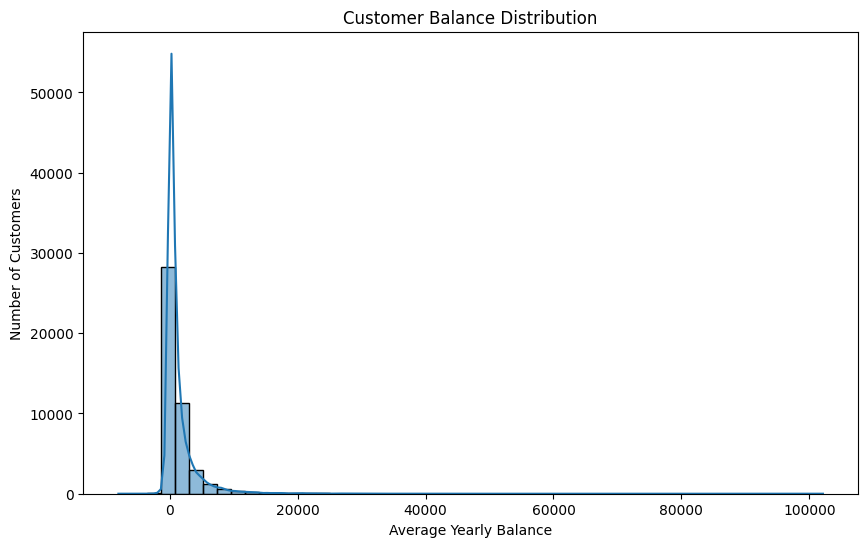

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="balance",
    bins=50,
    kde=True
)

plt.title("Customer Balance Distribution")
plt.xlabel("Average Yearly Balance")
plt.ylabel("Number of Customers")

plt.show()

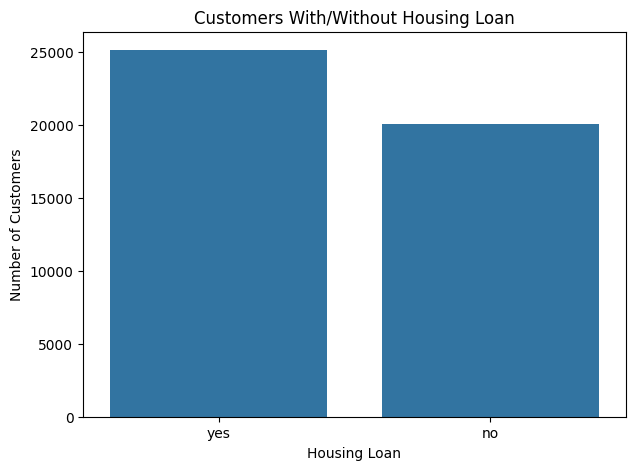

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="housing"
)

plt.title("Customers With/Without Housing Loan")
plt.xlabel("Housing Loan")
plt.ylabel("Number of Customers")

plt.show()

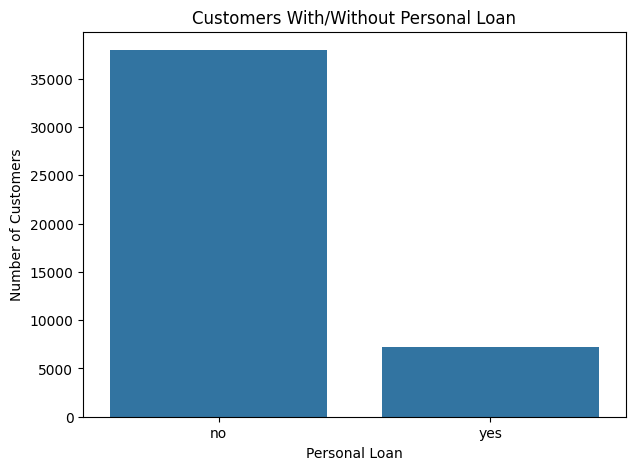

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="loan"
)

plt.title("Customers With/Without Personal Loan")
plt.xlabel("Personal Loan")
plt.ylabel("Number of Customers")

plt.show()

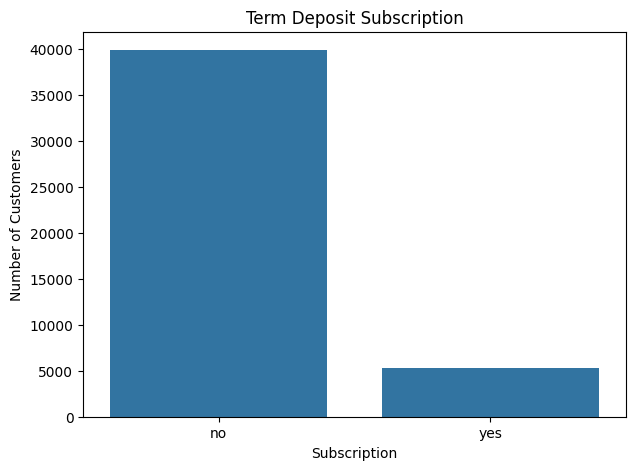

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="subscription"
)

plt.title("Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

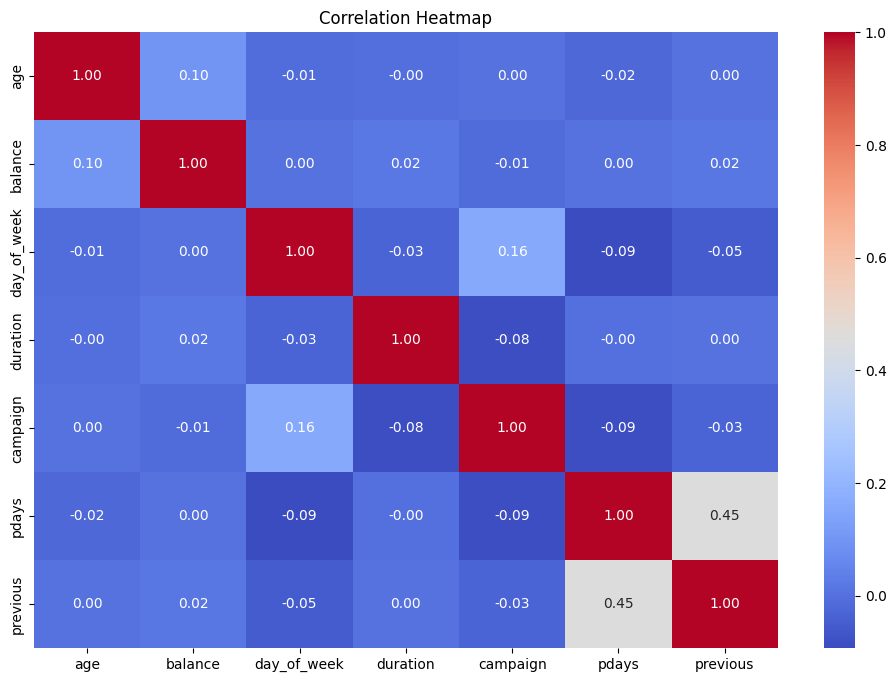

In [23]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include=["int64", "float64"]
).corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [51]:
df["engagement_score"] = (
    df["balance"].rank(pct=True) * 0.40 +
    df["previous"].rank(pct=True) * 0.20 +
    df["duration"].rank(pct=True) * 0.20 +
    (1 / (df["campaign"] + 1)).rank(pct=True) * 0.20
)

print("Engagement score created!")
display(
    df[
        [
            "balance",
            "previous",
            "duration",
            "campaign",
            "engagement_score"
        ]
    ].head()
)

Engagement score created!


,balance,previous,duration,campaign,engagement_score
0,2143,0,261,1,0.706448
1,29,0,151,1,0.408887
2,2,0,76,1,0.340649
3,1506,0,92,1,0.589040
4,1,0,198,1,0.416980


In [25]:
df["customer_category"] = pd.qcut(
    df["engagement_score"],
    q=4,
    labels=[
        "Low Value",
        "Regular",
        "High Value",
        "Premium"
    ]
)

print("Customer categories created!")

print(
    df["customer_category"].value_counts()
)

Customer categories created!
customer_category
Low Value     11303
Regular       11303
Premium       11303
High Value    11302
Name: count, dtype: int64


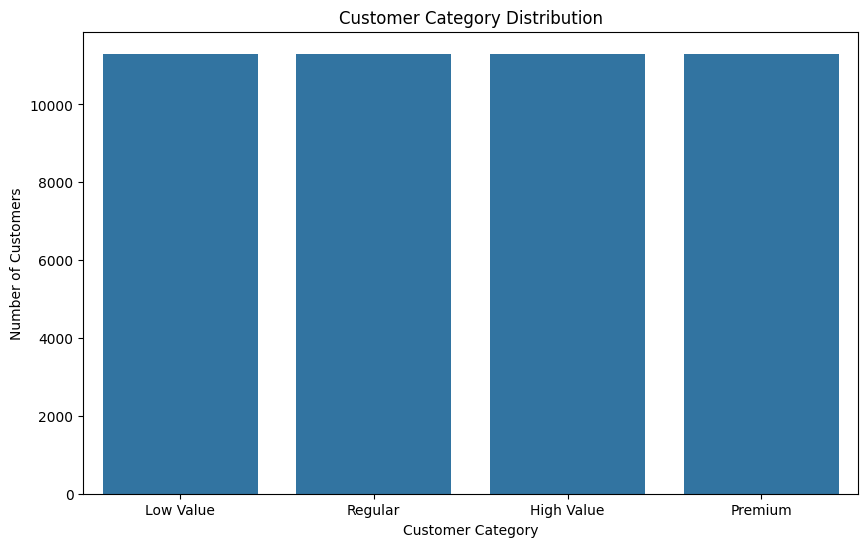

In [26]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="customer_category",
    order=[
        "Low Value",
        "Regular",
        "High Value",
        "Premium"
    ]
)

plt.title("Customer Category Distribution")
plt.xlabel("Customer Category")
plt.ylabel("Number of Customers")

plt.show()

In [27]:
features_to_remove = [
    "customer_category",
    "engagement_score",
    "balance",
    "duration",
    "previous",
    "campaign",
    "subscription"
]

X = df.drop(
    columns=features_to_remove
)

y = df["customer_category"]

print("Final features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Final features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'pdays', 'poutcome']

Target:
customer_category


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 36168
Testing records: 9043


In [29]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'day_of_week', 'pdays']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [30]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [31]:
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                multi_class="multinomial",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Multinomial Logistic Regression model created!")

Multinomial Logistic Regression model created!


In [32]:
model.fit(
    X_train,
    y_train
)

print("Model training completed!")

Model training completed!


In [33]:
y_pred = model.predict(X_test)

print("Predictions generated!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated!

First 20 predictions:
['High Value' 'Low Value' 'Premium' 'Premium' 'Low Value' 'Regular'
 'Low Value' 'Low Value' 'Low Value' 'Low Value' 'High Value' 'Regular'
 'Low Value' 'Regular' 'Low Value' 'Regular' 'Premium' 'Regular'
 'High Value' 'Premium']


In [34]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

Accuracy: 37.08 %


In [35]:
precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "Precision:",
    round(precision, 4)
)

Precision: 0.355


In [36]:
recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "Recall:",
    round(recall, 4)
)

Recall: 0.3708


In [37]:
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "F1 Score:",
    round(f1, 4)
)

F1 Score: 0.3499


In [38]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  High Value       0.30      0.15      0.20      2260
   Low Value       0.38      0.58      0.46      2261
     Premium       0.45      0.51      0.48      2261
     Regular       0.29      0.23      0.26      2261

    accuracy                           0.37      9043
   macro avg       0.36      0.37      0.35      9043
weighted avg       0.36      0.37      0.35      9043



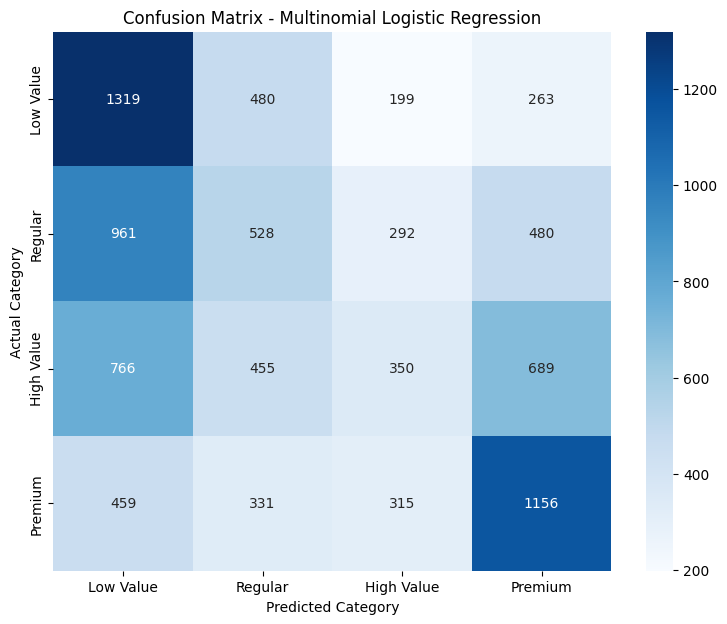

In [39]:
classes = [
    "Low Value",
    "Regular",
    "High Value",
    "Premium"
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title(
    "Confusion Matrix - Multinomial Logistic Regression"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

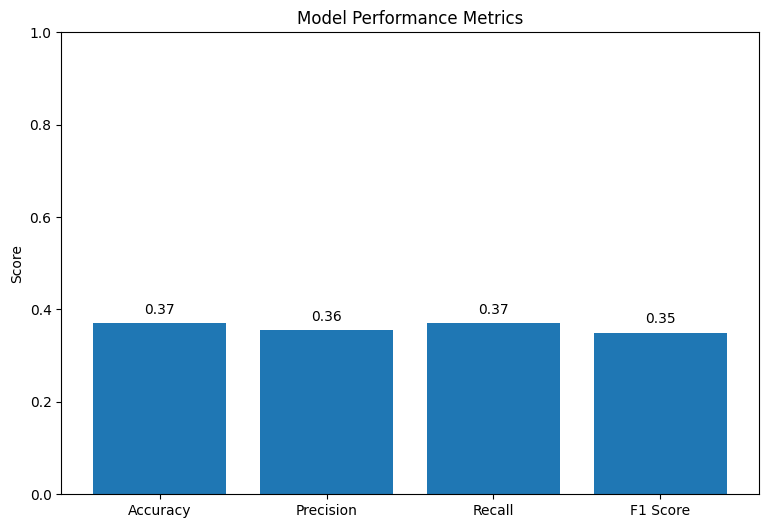

In [40]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(9, 6))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 1)

plt.title(
    "Model Performance Metrics"
)

plt.ylabel("Score")

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.show()

In [41]:
# Get prediction probabilities
y_probability = model.predict_proba(X_test)

# Convert actual labels to one-hot format
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

roc_auc = roc_auc_score(
    y_test_binary,
    y_probability,
    multi_class="ovr",
    average="weighted"
)

print(
    "Weighted Multi-Class ROC-AUC:",
    round(roc_auc, 4)
)

Weighted Multi-Class ROC-AUC: 0.4476


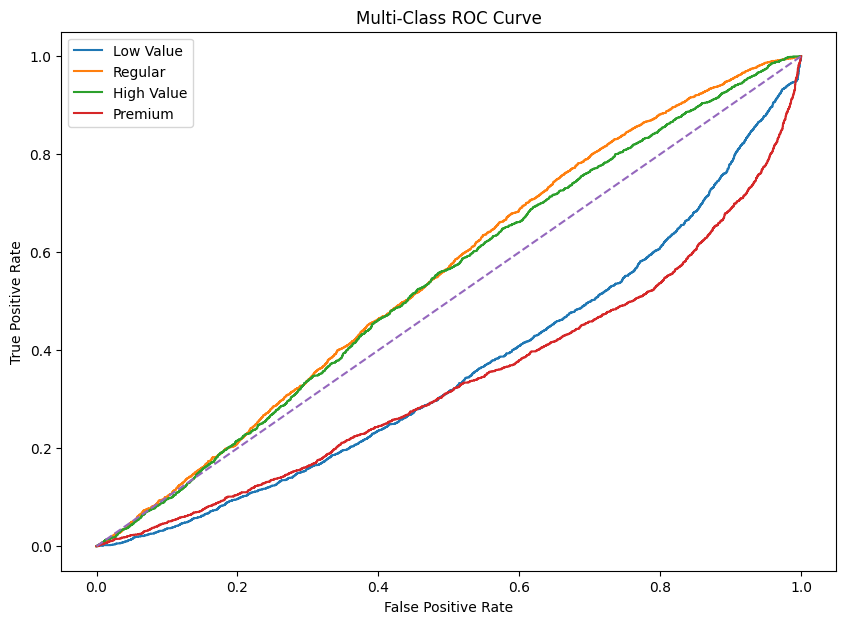

In [42]:
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_probability[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=class_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title(
    "Multi-Class ROC Curve"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

In [43]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(results)

,Metric,Score
0,Accuracy,0.370784
1,Precision,0.355026
2,Recall,0.370784
3,F1 Score,0.349928
4,ROC-AUC,0.447649


In [44]:
joblib.dump(
    model,
    "customer_category_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [45]:
results.to_csv(
    "model_results.csv",
    index=False
)

print("Model results saved!")

Model results saved!


In [46]:
from google.colab import files

files.download(
    "customer_category_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
!pip install gradio

In [48]:
import gradio as gr

In [50]:
def predict_customer(
    age,
    job,
    marital,
    education,
    default,
    housing,
    loan,
    contact,
    day,
    month,
    poutcome
):

    customer = pd.DataFrame({
        "age": [age],
        "job": [job],
        "marital": [marital],
        "education": [education],
        "default": [default],
        "housing": [housing],
        "loan": [loan],
        "contact": [contact],
        "day": [day],
        "month": [month],
        "poutcome": [poutcome]
    })

    prediction = model.predict(customer)[0]

    probabilities = model.predict_proba(customer)[0]

    probability_dict = {
        classes[i]: round(
            float(probabilities[i]) * 100,
            2
        )
        for i in range(len(classes))
    }

    return prediction, probability_dict